# Phase 2b -- validation: can the Phase 2 pairs be trusted?

Phase 2 rests on one choice: a **conditional pair test** that respects each tumour's own
alteration count, fitted within subtypes. Three checks, each answering one question:

| § | Question | Check | Script |
|---|---|---|---|
| 1 | Do the pairs hold in **different patients**? | re-test in TCGA | `14_tcga_external_validation.py` |
| 2 | Are they **known biology**? | literature and the SelectSim atlas | `19_novelty_screen.py` |
| 3 | Is our test **better than published methods**? | same data, five methods | `15_method_benchmark.py` |

The scripts take minutes to hours (TCGA download, permutation nulls); this notebook only reads
their saved outputs. Further side analyses (mutation-load check, ranking by effect size, gene sets,
dN/dS, shrinkage across cancer types) are in notebook 02c.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import false_discovery_control

P = "../data/processed/"
pd.set_option("display.width", 160)
tv = pd.read_parquet(P + "tcga_validation.parquet")

## 1. External validation in TCGA

TCGA PanCancer Atlas: different patients, whole-exome sequencing, different centres and callers.
The same pairs are re-tested with the same conditional test after applying the Phase 1 filters
as closely as TCGA allows (non-hypermutated patients; TCGA study as the subtype stratum).
TCGA has about 1/20 of GENIE's patients, so many pairs cannot be tested there; the question is
whether the ones that can **keep their direction**.

In [2]:
t = tv[tv.tcga_p.notna()]
rows = []
for name, sel in [("replicated candidates", t.interaction_candidate & t.replicated),
                  ("all candidates", t.interaction_candidate),
                  ("not significant in GENIE (control)", t.q_value >= 0.05)]:
    g = t[sel]; same = g.tcga_direction == g.direction
    sig_same = (g.tcga_p < .05) & same
    rows.append({"group": name, "testable in TCGA": len(g),
                 "same direction": f"{same.sum()} ({same.mean():.0%})",
                 "significant in TCGA, same direction": f"{sig_same.sum()} ({sig_same.mean():.0%})",
                 "significant in TCGA, opposite direction": int(((g.tcga_p < .05) & ~same).sum())})
pd.DataFrame(rows).set_index("group")

,testable in TCGA,same direction,"significant in TCGA, same direction","significant in TCGA, opposite direction"
group,,,,
replicated candidates,316,297 (94%),144 (46%),0
all candidates,765,675 (88%),248 (32%),0
not significant in GENIE (control),1317,907 (69%),97 (7%),13


**Stronger in GENIE, more often confirmed in TCGA.** Candidates split into four equal groups by
their GENIE q-value. If the significant pairs were noise, the TCGA agreement would not depend on how
strong the GENIE signal is.

In [3]:
c = t[t.interaction_candidate].copy()
c["GENIE strength"] = pd.qcut(c.q_value.rank(method="first"), 4,
                              labels=["strongest quarter", "2nd", "3rd", "weakest quarter"])
same = c.tcga_direction == c.direction
c = c.assign(same_direction=same, significant_same_direction=same & (c.tcga_p < .05))
c.groupby("GENIE strength", observed=True)[["same_direction", "significant_same_direction"]].mean().round(2)

,same_direction,significant_same_direction
GENIE strength,,
strongest quarter,0.98,0.66
2nd,0.91,0.29
3rd,0.86,0.20
weakest quarter,0.78,0.15


In [4]:
# Effect size in both cohorts, every candidate testable in TCGA (Figure panel b)
from scipy.stats import spearmanr
g = np.log2((c.n_both_altered + .5) / (c.expected_both + .5))
tc = np.log2((c.tcga_n_both + .5) / (c.tcga_expected + .5))
print(f"{len(c)} candidates; Spearman correlation of GENIE vs TCGA effect: {spearmanr(g, tc)[0]:.2f}")

765 candidates; Spearman correlation of GENIE vs TCGA effect: 0.74


In [5]:
# Well-known pairs: GENIE vs TCGA effect side by side
known = [("Non-Small Cell Lung Cancer", "KEAP1", "STK11"), ("Glioma", "ATRX", "IDH1"), ("Glioma", "IDH1", "TP53"),
         ("Glioma", "CDKN2A", "EGFR"), ("Breast Cancer", "PIK3CA", "PTEN"), ("Colorectal Cancer", "BRAF", "KRAS"),
         ("Melanoma", "BRAF", "NRAS"), ("Non-Small Cell Lung Cancer", "EGFR", "KRAS")]
k = pd.concat([t[(t.Cancer_Type == c) & (t.Gene_A.isin([a, b])) & (t.Gene_B.isin([a, b]))] for c, a, b in known])
k.assign(tcga_fold=(k.tcga_n_both / k.tcga_expected).round(2))[
    ["Cancer_Type", "Gene_A", "Gene_B", "fold_enrichment", "q_value", "tcga_n_both", "tcga_expected", "tcga_fold", "tcga_p"]].round(4)

,Cancer_Type,Gene_A,Gene_B,fold_enrichment,q_value,tcga_n_both,tcga_expected,tcga_fold,tcga_p
851,Non-Small Cell Lung Cancer,KEAP1,STK11,4.3031,0.0,20.0,9.1248,2.19,0.0016
1533,Glioma,ATRX,IDH1,1.7262,0.0,200.0,152.4631,1.31,0.0000
1754,Glioma,IDH1,TP53,1.5290,0.0,252.0,200.6538,1.26,0.0000
1602,Glioma,CDKN2A,EGFR,1.3220,0.0,156.0,118.8124,1.31,0.0000
536,Breast Cancer,PIK3CA,PTEN,0.6771,0.0,18.0,40.7944,0.44,0.0000
1145,Colorectal Cancer,BRAF,KRAS,0.1587,0.0,2.0,9.1771,0.22,0.0088
4872,Melanoma,BRAF,NRAS,0.0857,0.0,1.0,15.0703,0.07,0.0000
764,Non-Small Cell Lung Cancer,EGFR,KRAS,0.0761,0.0,4.0,22.4932,0.18,0.0000


**Reading.** Replicated candidates keep their direction in TCGA almost always and are
significant there several times more often than the control pairs; none is significant the other
way. The out-of-centre replication flag (notebook 02, Step 6a) is therefore a useful confidence label, and
the control row shows the agreement is not an artefact of shared gene frequencies. Agreement rises with
the strength of the GENIE signal (98% same direction and 66% significant in the strongest quarter), and
effect sizes correlate across the cohorts (rho = 0.74).

## 2. Agreement with known biology

The 386 robust pairs (replicated candidates, Phase 4) were checked against the literature (Europe PMC
titles and abstracts: how often the two genes are reported together, and as an interaction in that
cancer type) and against the SelectSim atlas (Iyer ... Ciriello, Nat Genet 2026; 892 validated
mutation-only pairs). SelectSim covers mutations only, so copy-number and fusion pairs cannot appear in it.

In [6]:
nv = pd.read_parquet(P + "novelty_screen.parquet")
display(pd.DataFrame({"pairs": nv.novelty.value_counts()}))
display(pd.DataFrame({"pairs": nv.selectsim.value_counts()}))
print(f"reported as an interaction in the same cancer type: {(nv.papers_interaction_in_type > 0).mean():.0%}")

,pairs
novelty,
well known,234
some reports,109
rarely or never reported,43


,pairs
selectsim,
not reported,245
"same type, same direction",79
pan-cancer only,62


reported as an interaction in the same cancer type: 72%


**Reading.** Most robust pairs are known biology (234 well known, 109 with some reports), which is
what a well-behaved test should recover. Every pair SelectSim reports for the same cancer type agrees in
direction; none is opposite. The 43 rarely reported pairs are examined in Phase 4 (novelty audit): they
are amplicon passengers or subtype markers, not new driver interactions.

## 3. Head-to-head benchmark of the method families

All methods run on the **same** patients, genes and pairs (9 large cancer types):

- **A Fisher** -- what cBioPortal and maftools report;
- **B1 DISCOVER-style** -- per-tumour rates plugged in as known (Canisius 2016);
- **B2 conditional** -- our test without subtype strata; **B3** -- with strata (Phase 2);
- **D SELECT** (Mina 2017), re-implemented from its Methods S1: weighted mutual information with a
  per-subtype sample-count correction, an empirical null from 1,000 margin-preserving
  randomisations within subtypes, effect size and empirical FDR. Not reproduced: randomising each
  alteration type separately (all methods see one gene-level matrix) and its correction for indirect
  links (a network step).

**(1) Null calibration** uses a curveball-permuted null: matrices that keep every gene's and every
tumour's alteration count but break any real pairing. Share of null pairs with p < 0.05 (target 5%):

In [7]:
mb = pd.read_parquet(P + "method_benchmark.parquet")
nb_null = pd.read_parquet(P + "method_benchmark_null.parquet")
M = {"A Fisher": ("p_fisher", "dir_fisher"), "B1 DISCOVER-style": ("p_discover", "dir_discover"),
     "B2 conditional": ("p_conditional", "dir_conditional"), "B3 conditional + subtype": ("p_cond_subtype", "dir_cond_subtype"),
     "D SELECT": ("p_select", "dir_select")}


def qv(df, pc):   # SELECT reports its own empirical FDR; the others use Benjamini-Hochberg
    return df["q_select"].to_numpy() if pc == "p_select" else false_discovery_control(df[pc].clip(1e-300, 1))


pd.DataFrame([dict(method=n, null_p05=(nb_null[pc] < .05).mean(), null_after_FDR=(qv(nb_null, pc) < .05).mean())
              for n, (pc, _) in M.items()]).round(3)

,method,null_p05,null_after_FDR
0,A Fisher,0.114,0.006
1,B1 DISCOVER-style,0.327,0.181
2,B2 conditional,0.020,0.000
3,B3 conditional + subtype,0.019,0.000
4,D SELECT,0.038,0.002


**(2)**: significant calls on the real data and how often they replicate in TCGA.

In [8]:
rows = []
for name, (pc, dc) in M.items():
    q = qv(mb, pc)
    s = mb[(q < .05) & mb.tcga_p.notna()]
    rows.append(dict(method=name, significant=int((q < .05).sum()), testable_in_TCGA=len(s),
                     replicate_in_TCGA=((s.tcga_p < .05) & (s.tcga_direction == s[dc])).mean(),
                     significant_opposite=int(((s.tcga_p < .05) & (s.tcga_direction != s[dc])).sum())))
pd.DataFrame(rows).round(3)

,method,significant,testable_in_TCGA,replicate_in_TCGA,significant_opposite
0,A Fisher,990,632,0.286,0
1,B1 DISCOVER-style,1101,609,0.305,0
2,B2 conditional,853,523,0.338,0
3,B3 conditional + subtype,677,422,0.370,0
4,D SELECT,770,487,0.337,0


**Reading.**
- **Calibration separates the methods.** Fisher roughly doubles the false-positive rate and the
  DISCOVER-style plug-in is far worse on panel data (it treats estimated rates as known). The two
  methods with a margin-preserving null -- our conditional test (exact) and SELECT (by randomisation)
  -- are both calibrated.
- **Precision follows calibration.** Our significant list is the shortest and the most reproducible
  in TCGA (37% vs 34% for SELECT and 29% for Fisher).
- Ranked by effect size instead of significance, SELECT's 50 strongest pairs replicate slightly more
  often than ours (96% vs 86%); beyond the top 100 the calibrated methods are similar (notebook 02c, Section M).
- The method choice matters most for the *long tail* of moderate effects, which is exactly where a
  clinical lookup tool is queried.

Figure -- Phase 2b at a glance. **a** TCGA: share of pairs testable there that keep their direction (light) and are
also significant (dark), with the number of pairs under each group (Section 1); **b** effect in GENIE vs TCGA for every
candidate testable in both, well-known pairs circled (Section 1); **c** the benchmark: false alarms on data with no real
links, and how often each method's calls are confirmed in TCGA (Section 3); **d** agreement with the literature and the
SelectSim atlas (Section 2).  
*Drawn by
`scripts/figures/phase2b_validation.R` -> `results/figures/phase2b_validation/figure_phase2b.pdf`*

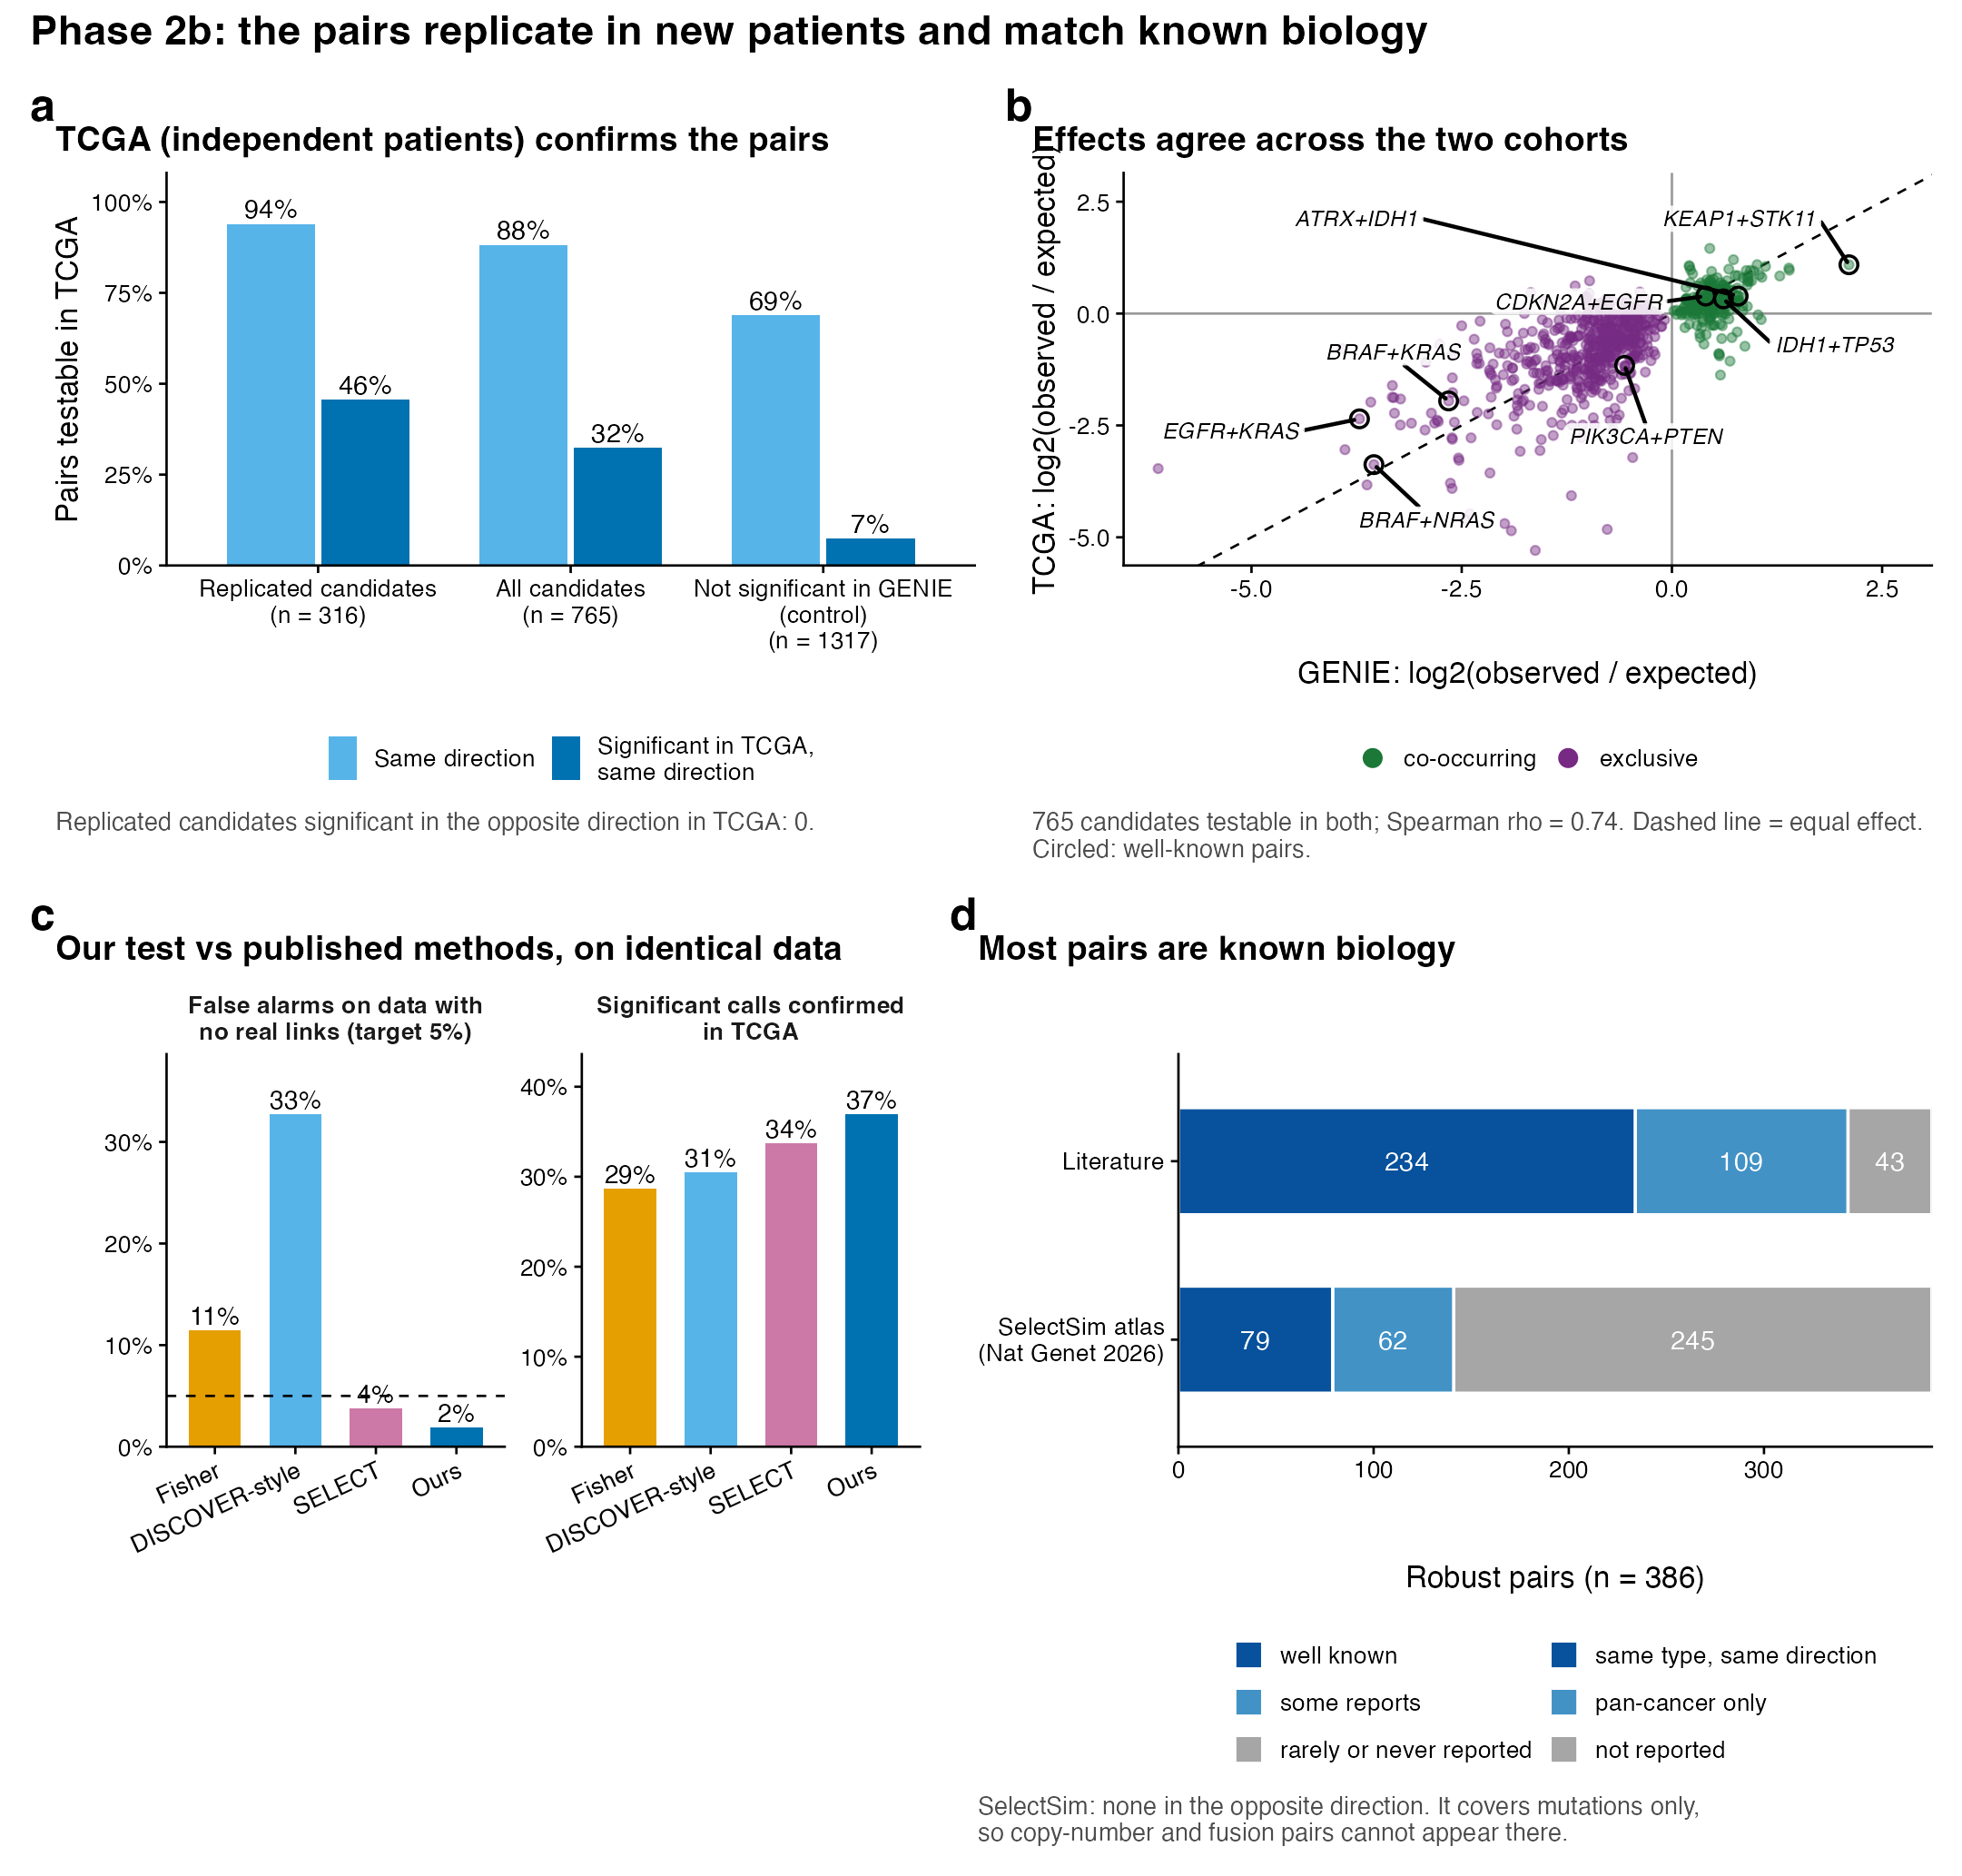

In [9]:
import subprocess, sys
from IPython.display import Image, display

# Rebuild this figure from the saved outputs: export small CSVs, then run the R script
subprocess.run([sys.executable, "scripts/figures/00_export_figure_data.py"], cwd="..", check=True, capture_output=True)
subprocess.run(["Rscript", "scripts/figures/phase2b_validation.R"], cwd="..", check=True, capture_output=True)
display(Image(filename="../results/figures/phase2b_validation/figure_phase2b.png", width=1000))

## Discussion

1. **The pairs hold in independent patients.** Of the replicated candidates TCGA can test, 94% point
   the same way and 46% are significant there; none is significant the other way. Control pairs
   (not significant in GENIE) are significant in TCGA only 7% of the time. The stronger the GENIE
   signal, the more often TCGA confirms it, and effect sizes correlate (rho = 0.74).
2. **They are mostly known biology.** 234 of 386 robust pairs are well known and 109 have some reports;
   every pair also in the SelectSim atlas for the same cancer type agrees in direction.
3. **The test is calibrated, and its calls replicate best.** Only the methods with a margin-preserving
   null (our conditional test and SELECT) stay below 5% false alarms; our significant list is the most
   reproducible in TCGA (37% vs 34% SELECT, 31% DISCOVER-style, 29% Fisher).
4. **The advantage is in the long tail.** All methods find KEAP1/STK11 or EGFR/KRAS; they disagree on
   moderate effects -- where a clinician's lookup query usually lands.